#### Notebook 04 — LSTM baselines (Local + Centralized + Federated)

**Purpose.** This notebook is an architecture ablation of Notebook 03. The
preprocessing tensors, the clients, the splits, the class definitions, the
training-strategy structure, the hyperparameter sweep, and the evaluation
protocol are all identical to Notebook 03. The only thing that changes is
the recurrent unit: **GRU → LSTM**. This isolates the effect of the
recurrent architecture from every other experimental factor.

**Reporting structure.** Each baseline (Local, Centralized, Federated) is
presented in two phases — first a training-behavior analysis (per-epoch or
per-round trajectories with summary tables and curves), then a test-set
evaluation. The two phases are reported in this order because learning
dynamics inform the interpretation of generalization. A final cross-
architecture comparison (Section 12) reports per-variant LSTM vs GRU
deltas, with the GRU values loaded live from the Notebook 03 saved CSVs.

**Inputs.**
- Preprocessed sequence tensors from Notebook 02
- GRU baseline reference values from Notebook 03

**Outputs.** Per-client training summaries and curves, per-client test
metrics, per-class reports, modal-density-stratified results, full
LSTM-vs-GRU comparison tables, saved model state-dicts, and a manifest.

## Section 0 — Setup

In [1]:
# 0.1 — Imports
import os, json, time, random, copy, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

print("Imports ready.")

Imports ready.


In [2]:
# 0.2 — Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU   : {torch.cuda.get_device_name(0)}")

Device: cuda
GPU   : Tesla T4


In [3]:
# 0.3 — Paths
# Auto-discover Notebook 02 outputs
n02_candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    if "preprocess_manifest.json" in files:
        n02_candidates.append(Path(root))
assert n02_candidates, (
    "No preprocess_manifest.json found under /kaggle/input. "
    "Attach Notebook 02 outputs as a Kaggle dataset."
)
PREPROCESS_DIR = n02_candidates[0]
TENSOR_DIR     = PREPROCESS_DIR / "tensors"
MANIFEST_PATH  = PREPROCESS_DIR / "preprocess_manifest.json"

# Auto-discover Notebook 03 outputs (must contain the all-variants test CSV)
n03_candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    if "federated_all_variants_test_results.csv" in files:
        n03_candidates.append(Path(root))
assert n03_candidates, (
    "Notebook 03 outputs not found under /kaggle/input. "
    "Attach the dataset that contains "
    "'federated_all_variants_test_results.csv' (the updated N03 outputs)."
)
GRU_AUDIT_DIR = n03_candidates[0]

OUTPUT_DIR = Path("/kaggle/working/lstm_baselines")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(MODELS_DIR := OUTPUT_DIR / "models").mkdir(exist_ok=True)
(AUDIT_DIR  := OUTPUT_DIR / "audit").mkdir(exist_ok=True)
(PREDS_DIR  := OUTPUT_DIR / "predictions").mkdir(exist_ok=True)

print(f"Notebook 02 dir: {PREPROCESS_DIR}")
print(f"Notebook 03 dir: {GRU_AUDIT_DIR}")
print(f"Output dir     : {OUTPUT_DIR}")

Notebook 02 dir: /kaggle/input/datasets/sarahaddouda/preprocess-outputs
Notebook 03 dir: /kaggle/input/datasets/sarahaddouda/gru-baselines/audit
Output dir     : /kaggle/working/lstm_baselines


In [4]:
# 0.4 — Constants (frozen — must match Notebook 02 and Notebook 03)
ACTIVE_CLIENTS = ["England", "Ireland", "USA"]
FEATURE_COLS   = ["NH3", "BOD", "DO", "PO4", "pH", "Temp", "Nitrogen", "Nitrate"]
SPLITS         = ["train", "val", "test"]

WINDOW    = 12
N_FEATS   = len(FEATURE_COLS)
N_CLASSES = 5

CCME_CLASS_ORDER = ["Excellent", "Good", "Fair", "Marginal", "Poor"]
INT_TO_CLASS = {i: c for i, c in enumerate(CCME_CLASS_ORDER)}
CLASS_NAMES  = CCME_CLASS_ORDER

print(f"Active clients : {ACTIVE_CLIENTS}")
print(f"Features ({N_FEATS}): {FEATURE_COLS}")
print(f"Classes ({N_CLASSES}) : {CLASS_NAMES}")

Active clients : ['England', 'Ireland', 'USA']
Features (8): ['NH3', 'BOD', 'DO', 'PO4', 'pH', 'Temp', 'Nitrogen', 'Nitrate']
Classes (5) : ['Excellent', 'Good', 'Fair', 'Marginal', 'Poor']


## Section 1 — Load tensors and GRU baselines

We load the same Notebook 02 `.npz` archives that the GRU baselines used,
and we also load the GRU baseline reference values from the Notebook 03
audit CSVs. All cross-architecture comparison tables in Section 12 are
built from those live CSVs — no hardcoded reference values appear anywhere
in this notebook.

In [5]:
# 1.1 — Load preprocessing manifest and tensors
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    preprocess_manifest = json.load(f)

data = {}
for client in ACTIVE_CLIENTS:
    npz_path = TENSOR_DIR / f"{client.lower()}_stage1_sequences.npz"
    assert npz_path.exists(), f"Missing tensor file: {npz_path}"
    archive = np.load(npz_path, allow_pickle=True)
    data[client] = {}
    for split in SPLITS:
        data[client][split] = {
            "X":            archive[f"X_{split}"],
            "y":            archive[f"y_{split}"],
            "mask":         archive[f"mask_{split}"],
            "site_ids":     archive[f"site_ids_{split}"],
            "target_dates": archive[f"target_dates_{split}"],
        }
    archive.close()

print("Loaded tensors:")
for client in ACTIVE_CLIENTS:
    sizes = " | ".join(
        f"{s}={data[client][s]['X'].shape[0]:>6,}"
        for s in SPLITS
    )
    print(f"  [{client:<8}] {sizes}")

Loaded tensors:
  [England ] train=76,530 | val= 8,490 | test=11,942
  [Ireland ] train=27,778 | val= 4,296 | test= 5,887
  [USA     ] train=30,222 | val= 1,770 | test= 1,979


In [6]:
# 1.2 — Verify tensors against the Notebook 02 manifest
verify_rows = []
for client in ACTIVE_CLIENTS:
    expected_counts = preprocess_manifest["sequence_counts"][client]
    for split in SPLITS:
        X = data[client][split]["X"]
        y = data[client][split]["y"]
        mask = data[client][split]["mask"]
        ok = (
            X.shape == mask.shape
            and X.ndim == 3
            and X.shape[1:] == (WINDOW, N_FEATS)
            and y.shape == (X.shape[0],)
            and X.shape[0] == expected_counts[split]
            and np.isfinite(X).all()
            and y.min() >= 0 and y.max() < N_CLASSES
        )
        verify_rows.append({
            "Client": client, "Split": split,
            "N": X.shape[0], "X_shape": str(tuple(X.shape)),
            "OK": "ok" if ok else "FAIL",
        })

verify_df = pd.DataFrame(verify_rows)
display(verify_df)
assert (verify_df["OK"] == "ok").all(), "Tensor verification failed."
print("\nAll tensors verified.")

,Client,Split,N,X_shape,OK
0,England,train,76530,"(76530, 12, 8)",ok
1,England,val,8490,"(8490, 12, 8)",ok
2,England,test,11942,"(11942, 12, 8)",ok
3,Ireland,train,27778,"(27778, 12, 8)",ok
4,Ireland,val,4296,"(4296, 12, 8)",ok
5,Ireland,test,5887,"(5887, 12, 8)",ok
6,USA,train,30222,"(30222, 12, 8)",ok
7,USA,val,1770,"(1770, 12, 8)",ok
8,USA,test,1979,"(1979, 12, 8)",ok



All tensors verified.


In [7]:
# 1.3 — Load GRU baseline reference values from Notebook 03
gru_local_df       = pd.read_csv(GRU_AUDIT_DIR / "local_test_summary.csv")
gru_centralized_df = pd.read_csv(GRU_AUDIT_DIR / "centralized_test_summary.csv")
gru_all_fed_df     = pd.read_csv(GRU_AUDIT_DIR / "federated_all_variants_test_results.csv")
gru_fed_val_df     = pd.read_csv(GRU_AUDIT_DIR / "federated_validation_comparison.csv")

# Sanity: assert all needed columns are there
for df, needed in [
    (gru_local_df,       ["Client", "Macro_F1_present_classes"]),
    (gru_centralized_df, ["Client", "Macro_F1_present_classes"]),
    (gru_all_fed_df,     ["Variant", "Client", "Macro_F1_present_classes"]),
]:
    for col in needed:
        assert col in df.columns, f"Missing column '{col}' in GRU baseline file."

print("Loaded GRU baseline reference values:")
print(f"  local       : {len(gru_local_df)} rows")
print(f"  centralized : {len(gru_centralized_df)} rows")
print(f"  federated (all variants): {len(gru_all_fed_df)} rows "
      f"({gru_all_fed_df['Variant'].nunique()} variants × {gru_all_fed_df['Client'].nunique()} clients)")

Loaded GRU baseline reference values:
  local       : 3 rows
  centralized : 3 rows
  federated (all variants): 18 rows (6 variants × 3 clients)


## Section 2 — Architecture and hyperparameter rationale

Every choice below is fixed to match Notebook 03 (the GRU experiment) so
that the comparison isolates the effect of the recurrent unit. The only
intentional architectural difference is the unit itself.

### Architecture

| Choice | Value | Reason |
|---|---|---|
| Model family | LSTM | Architecture under test. Compared against the GRU baseline of Notebook 03. |
| Hidden size | 64 | Same as GRU. We match hidden size rather than parameter count; the LSTM therefore has ~30% more parameters (~18.7k vs ~14.5k) due to its four-gate cell. This is the standard recurrent-architecture comparison protocol and is disclosed in the thesis. |
| Number of layers | 1 | Same as GRU. |
| Dropout | 0.2 | Same as GRU. |
| Read-out | last hidden state `h_n` → Linear(64 → 5); cell state `c_n` discarded | Standard LSTM-as-encoder convention. Mirrors GRU's last-hidden-state read-out. |

### Training

| Choice | Value | Reason |
|---|---|---|
| Loss | class-weighted cross-entropy (local / centralized); variant-dependent (federated) | Same as Notebook 03. |
| Optimizer | Adam | Same. |
| Learning rate (local + centralized) | 1e-3 | Same. |
| Learning rate (federated) | 5e-4 | Same. |
| Weight decay | 1e-4 | Same. |
| Gradient clip norm | 1.0 | Same. |
| Batch size | 256 | Same. |
| Max epochs | 50 | Same. |
| Early-stopping patience | 10 | Same. |
| Selection metric | macro-F1 | Same. |

### Federated specifics — variant structure mirrors GRU exactly

| Variant | Loss | Learning rate | µ | Matched GRU variant |
|---|---|---|---|---|
| FedAvg_v1  | per-client weighted CE | 1e-3 | — | GRU_FedAvg_v1 |
| FedAvg_v2  | pooled weighted CE     | 5e-4 | — | GRU_FedAvg_v2 |
| FedAvg_v3  | unweighted CE          | 5e-4 | — | GRU_FedAvg_v3 |
| FedProx_v1 | unweighted CE + prox.  | 5e-4 | 0.01   | GRU_FedProx_v1 |
| FedProx_v2 | unweighted CE + prox.  | 5e-4 | 0.001  | GRU_FedProx_v2 |
| FedProx_v3 | unweighted CE + prox.  | 5e-4 | 0.0001 | GRU_FedProx_v3 |

This one-to-one variant alignment is the central methodological feature
of this notebook: any LSTM-vs-GRU performance gap reported in Section 12
is measured at **constant loss strategy, constant learning rate, and
constant proximal coefficient**. Only the recurrent unit differs.

## Section 3 — Model and shared utilities

The training and evaluation infrastructure is identical to Notebook 03,
with `LSTMClassifier` replacing `GRUClassifier`.

In [8]:
# 3.1 — SequenceDataset
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [9]:
# 3.2 — LSTM classifier
class LSTMClassifier(nn.Module):
    """Single-layer LSTM + dropout + linear classification head."""
    def __init__(self, input_size=N_FEATS, hidden_size=64,
                 num_layers=1, num_classes=N_CLASSES, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # LSTM returns (output, (h_n, c_n)) — we discard the cell state
        _, (h_n, _) = self.lstm(x)
        h_last = h_n[-1]
        h_last = self.dropout(h_last)
        return self.classifier(h_last)


MODEL_CONFIG = {
    "input_size":  N_FEATS,
    "hidden_size": 64,
    "num_layers":  1,
    "num_classes": N_CLASSES,
    "dropout":     0.2,
}

TRAIN_CONFIG = {
    "batch_size":               256,
    "learning_rate":            1e-3,
    "weight_decay":             1e-4,
    "max_epochs":               50,
    "early_stopping_patience":  10,
    "lr_scheduler_patience":    3,
    "lr_scheduler_factor":      0.5,
    "gradient_clip_norm":       1.0,
    "primary_metric":           "macro_f1",
    "max_class_weight":         10.0,
}

def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

n_params = count_trainable_parameters(LSTMClassifier(**MODEL_CONFIG))
print(f"LSTMClassifier defined.")
print(f"  Trainable parameters: {n_params:,}")
print(f"  Architecture: {MODEL_CONFIG}")

LSTMClassifier defined.
  Trainable parameters: 19,269
  Architecture: {'input_size': 8, 'hidden_size': 64, 'num_layers': 1, 'num_classes': 5, 'dropout': 0.2}


In [10]:
# 3.3 — Loaders and metrics
def make_loader(X, y, batch_size, shuffle):
    ds = SequenceDataset(X, y)
    return DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle,
        num_workers=0, pin_memory=torch.cuda.is_available(),
    )


def compute_metrics(y_true, y_pred):
    return {
        "accuracy":          accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1":          f1_score(y_true, y_pred,
            labels=list(range(N_CLASSES)), average="macro", zero_division=0),
        "weighted_f1":       f1_score(y_true, y_pred,
            labels=list(range(N_CLASSES)), average="weighted", zero_division=0),
    }


def compute_test_metrics(y_true, y_pred):
    present_labels = sorted(np.unique(y_true).tolist())
    return {
        "accuracy":                 accuracy_score(y_true, y_pred),
        "balanced_accuracy":        balanced_accuracy_score(y_true, y_pred),
        "macro_f1_all_classes":     f1_score(y_true, y_pred,
            labels=list(range(N_CLASSES)), average="macro", zero_division=0),
        "macro_f1_present_classes": f1_score(y_true, y_pred,
            labels=present_labels, average="macro", zero_division=0),
        "weighted_f1":              f1_score(y_true, y_pred,
            labels=list(range(N_CLASSES)), average="weighted", zero_division=0),
        "present_classes":          ", ".join(INT_TO_CLASS[i] for i in present_labels),
    }

In [11]:
# 3.4 — Class-weight helper (with cap, consistent with Notebook 03)
def inverse_frequency_weights(y, cap=TRAIN_CONFIG["max_class_weight"]):
    counts = np.bincount(y, minlength=N_CLASSES).astype(np.float64)
    N = counts.sum()
    w = np.zeros(N_CLASSES, dtype=np.float64)
    present = counts > 0
    w[present] = N / (present.sum() * counts[present])
    w[present] = w[present] / w[present].mean()
    w = np.minimum(w, cap)
    if (w > 0).any():
        w[w > 0] = w[w > 0] / w[w > 0].mean()
    return w.astype(np.float32), counts.astype(int)

In [12]:
# 3.5 — Train / eval functions
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0; total_samples = 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device); y_batch = y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), TRAIN_CONFIG["gradient_clip_norm"]
        )
        optimizer.step()
        bs = X_batch.size(0)
        total_loss += loss.item() * bs; total_samples += bs
    return total_loss / total_samples


def evaluate(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0; total_samples = 0
    all_true, all_pred = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device); y_batch = y_batch.to(device)
            logits = model(X_batch)
            if criterion is not None:
                loss = criterion(logits, y_batch)
                total_loss += loss.item() * X_batch.size(0)
                total_samples += X_batch.size(0)
            preds = torch.argmax(logits, dim=1)
            all_true.append(y_batch.cpu().numpy())
            all_pred.append(preds.cpu().numpy())
    y_true = np.concatenate(all_true); y_pred = np.concatenate(all_pred)
    out = compute_metrics(y_true, y_pred)
    out["loss"] = total_loss / total_samples if total_samples > 0 else float("nan")
    out["y_true"], out["y_pred"] = y_true, y_pred
    return out


def predict(model, X, batch_size=TRAIN_CONFIG["batch_size"]):
    ds = SequenceDataset(X, np.zeros(len(X), dtype=np.int64))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    model.eval()
    all_pred, all_proba = [], []
    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(device)
            logits = model(X_batch)
            proba = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            all_pred.append(preds.cpu().numpy())
            all_proba.append(proba.cpu().numpy())
    return np.concatenate(all_pred), np.concatenate(all_proba)

In [13]:
# 3.6 — Generic supervised training loop with early stopping
def train_supervised(model, train_loader, val_loader, criterion, label=""):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max",
        factor=TRAIN_CONFIG["lr_scheduler_factor"],
        patience=TRAIN_CONFIG["lr_scheduler_patience"],
    )

    best_state, best_metric, best_epoch = None, -np.inf, 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, TRAIN_CONFIG["max_epochs"] + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
        val_metrics = evaluate(model, val_loader, criterion)
        val_macro_f1 = val_metrics["macro_f1"]
        scheduler.step(val_macro_f1)

        improved = val_macro_f1 > best_metric + 1e-6
        if improved:
            best_metric, best_epoch = val_macro_f1, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
            marker = "*"
        else:
            epochs_without_improvement += 1
            marker = ""

        history.append({
            "epoch": epoch, "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_macro_f1": val_macro_f1,
            "val_weighted_f1": val_metrics["weighted_f1"],
            "learning_rate": optimizer.param_groups[0]["lr"],
            "time_sec": time.time() - t0,
        })

        if label:
            print(f"[{label}] ep {epoch:02d} | "
                  f"train_loss={train_loss:.4f} | "
                  f"val_macro_f1={val_macro_f1:.4f} | "
                  f"val_acc={val_metrics['accuracy']:.4f} {marker}")

        if epochs_without_improvement >= TRAIN_CONFIG["early_stopping_patience"]:
            if label:
                print(f"[{label}] early stop at epoch {epoch}. "
                      f"Best epoch = {best_epoch}, best val_macro_f1 = {best_metric:.4f}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_metric,
        "n_epochs_run": len(history),
    }

In [14]:
# 3.7 — Smoke test on one real batch
loader = make_loader(
    data["Ireland"]["train"]["X"], data["Ireland"]["train"]["y"],
    batch_size=32, shuffle=True,
)
X_batch, y_batch = next(iter(loader))
model = LSTMClassifier(**MODEL_CONFIG).to(device)
X_batch = X_batch.to(device); y_batch = y_batch.to(device)
logits = model(X_batch)
loss = nn.CrossEntropyLoss()(logits, y_batch)
print(f"Input shape : {tuple(X_batch.shape)}")
print(f"Logits shape: {tuple(logits.shape)}")
print(f"Loss        : {loss.item():.4f}")
del model

Input shape : (32, 12, 8)
Logits shape: (32, 5)
Loss        : 1.5250


## Section 4 — Local LSTM baselines

Train one LSTM per client on that client's training data only. Same
training protocol as Notebook 03 Section 4. Reported as **(4.1) train all
clients → (4.2) inspect training behavior → (4.3) test evaluation**.

In [15]:
# 4.1 — Train a local LSTM on each client
local_models    = {}
local_histories = {}
local_summaries = {}

for client in ACTIVE_CLIENTS:
    print(f"\n=== Local LSTM: {client} (training) ===")
    weights, _ = inverse_frequency_weights(data[client]["train"]["y"])
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, device=device))

    train_loader = make_loader(
        data[client]["train"]["X"], data[client]["train"]["y"],
        TRAIN_CONFIG["batch_size"], shuffle=True,
    )
    val_loader = make_loader(
        data[client]["val"]["X"], data[client]["val"]["y"],
        TRAIN_CONFIG["batch_size"], shuffle=False,
    )

    model = LSTMClassifier(**MODEL_CONFIG).to(device)
    model, hist_df, summary = train_supervised(
        model, train_loader, val_loader, criterion, label=client[:3].upper()
    )
    local_models[client]    = model
    local_histories[client] = hist_df
    local_summaries[client] = summary

print("\nAll local LSTM models trained.")


=== Local LSTM: England (training) ===
[ENG] ep 01 | train_loss=0.8593 | val_macro_f1=0.6781 | val_acc=0.7218 *
[ENG] ep 02 | train_loss=0.6958 | val_macro_f1=0.7044 | val_acc=0.7271 *
[ENG] ep 03 | train_loss=0.6809 | val_macro_f1=0.7172 | val_acc=0.7496 *
[ENG] ep 04 | train_loss=0.6685 | val_macro_f1=0.6979 | val_acc=0.7510 
[ENG] ep 05 | train_loss=0.6637 | val_macro_f1=0.7197 | val_acc=0.7706 *
[ENG] ep 06 | train_loss=0.6570 | val_macro_f1=0.7165 | val_acc=0.7396 
[ENG] ep 07 | train_loss=0.6507 | val_macro_f1=0.7239 | val_acc=0.7609 *
[ENG] ep 08 | train_loss=0.6464 | val_macro_f1=0.7149 | val_acc=0.7485 
[ENG] ep 09 | train_loss=0.6416 | val_macro_f1=0.7175 | val_acc=0.7554 
[ENG] ep 10 | train_loss=0.6367 | val_macro_f1=0.7186 | val_acc=0.7545 
[ENG] ep 11 | train_loss=0.6355 | val_macro_f1=0.7048 | val_acc=0.7436 
[ENG] ep 12 | train_loss=0.6281 | val_macro_f1=0.7182 | val_acc=0.7617 
[ENG] ep 13 | train_loss=0.6251 | val_macro_f1=0.7274 | val_acc=0.7678 *
[ENG] ep 14 | trai

Local LSTM training summary:


,Client,Epochs_run,Best_epoch,Init_train_loss,Final_train_loss,Init_val_loss,Best_val_loss,Best_val_macro_F1,Best_val_accuracy
0,England,35,25,0.8593,0.6052,0.6516,0.5399,0.7403,0.7755
1,Ireland,27,17,1.3013,0.8179,0.8143,0.7114,0.3188,0.8308
2,USA,19,9,1.3272,0.7518,0.7128,0.4450,0.3361,0.9463


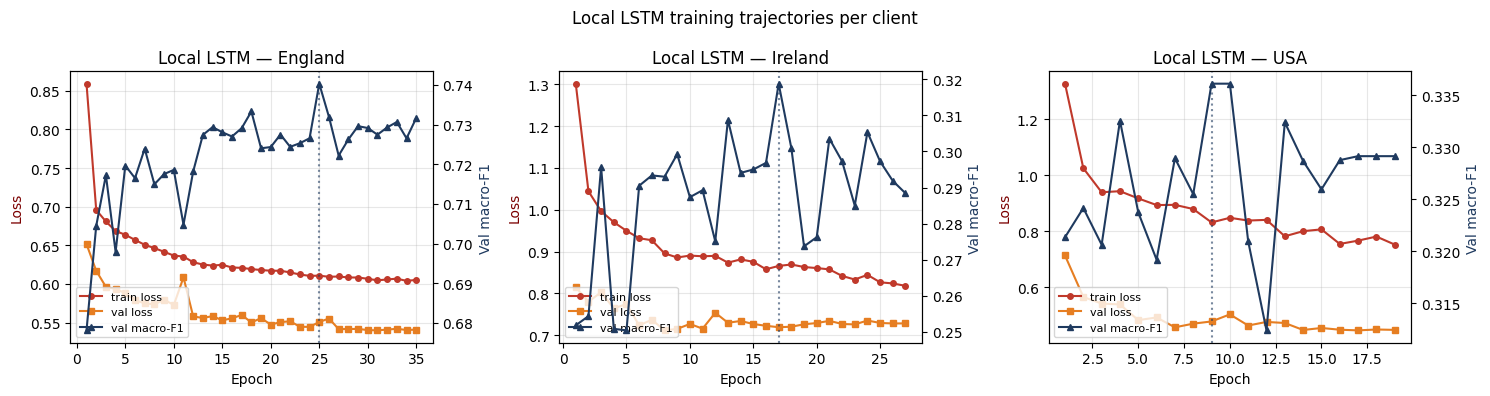

In [16]:
# 4.2 — Local LSTM training behavior: summary table + curves
local_train_summary_rows = []
for client in ACTIVE_CLIENTS:
    h = local_histories[client]
    best_row = h.loc[h["val_macro_f1"].idxmax()]
    local_train_summary_rows.append({
        "Client":              client,
        "Epochs_run":          len(h),
        "Best_epoch":          int(best_row["epoch"]),
        "Init_train_loss":     round(h["train_loss"].iloc[0], 4),
        "Final_train_loss":    round(h["train_loss"].iloc[-1], 4),
        "Init_val_loss":       round(h["val_loss"].iloc[0], 4),
        "Best_val_loss":       round(h["val_loss"].min(), 4),
        "Best_val_macro_F1":   round(best_row["val_macro_f1"], 4),
        "Best_val_accuracy":   round(best_row["val_accuracy"], 4),
    })
local_train_summary_df = pd.DataFrame(local_train_summary_rows)
local_train_summary_df.to_csv(AUDIT_DIR / "local_lstm_training_summary.csv", index=False)

print("Local LSTM training summary:")
display(local_train_summary_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, client in zip(axes, ACTIVE_CLIENTS):
    h = local_histories[client]
    ax2 = ax.twinx()
    ax.plot(h["epoch"], h["train_loss"], "o-", color="#C0392B",
            markersize=4, label="train loss")
    ax.plot(h["epoch"], h["val_loss"], "s-", color="#E67E22",
            markersize=4, label="val loss")
    ax2.plot(h["epoch"], h["val_macro_f1"], "^-", color="#1F3A5F",
             markersize=4, label="val macro-F1")
    best_ep = h.loc[h["val_macro_f1"].idxmax(), "epoch"]
    ax2.axvline(best_ep, color="#1F3A5F", linestyle=":", alpha=0.6)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss", color="#7B0000")
    ax2.set_ylabel("Val macro-F1", color="#1F3A5F")
    ax.set_title(f"Local LSTM — {client}")
    ax.grid(True, alpha=0.3)
    ln1, lab1 = ax.get_legend_handles_labels()
    ln2, lab2 = ax2.get_legend_handles_labels()
    ax.legend(ln1 + ln2, lab1 + lab2, loc="lower left", fontsize=8)
plt.suptitle("Local LSTM training trajectories per client")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "local_lstm_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [17]:
# 4.3 — Local LSTM test evaluation
local_test_metrics = {}
local_predictions  = {}
local_test_rows    = []
local_per_class    = []

for client in ACTIVE_CLIENTS:
    print(f"Evaluating local LSTM model on {client} test set")
    model = local_models[client]
    y_true = data[client]["test"]["y"]
    y_pred, y_proba = predict(model, data[client]["test"]["X"])

    m = compute_test_metrics(y_true, y_pred)
    local_test_metrics[client] = m
    local_predictions[client]  = {"y_true": y_true, "y_pred": y_pred, "y_proba": y_proba}

    local_test_rows.append({
        "Client":                   client,
        "N_test":                   len(y_true),
        "Best_epoch":               local_summaries[client]["best_epoch"],
        "Best_val_macro_F1":        round(local_summaries[client]["best_val_macro_f1"], 4),
        "Accuracy":                 round(m["accuracy"], 4),
        "Balanced_accuracy":        round(m["balanced_accuracy"], 4),
        "Macro_F1_all_classes":     round(m["macro_f1_all_classes"], 4),
        "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
        "Weighted_F1":              round(m["weighted_f1"], 4),
        "Present_classes":          m["present_classes"],
    })

    rep = classification_report(
        y_true, y_pred, labels=list(range(N_CLASSES)),
        target_names=CLASS_NAMES, zero_division=0, output_dict=True,
    )
    for cid, cname in enumerate(CLASS_NAMES):
        local_per_class.append({
            "Client": client, "Class_id": cid, "Class": cname,
            "Support":   int(rep[cname]["support"]),
            "Precision": round(rep[cname]["precision"], 4),
            "Recall":    round(rep[cname]["recall"], 4),
            "F1":        round(rep[cname]["f1-score"], 4),
        })

local_test_df      = pd.DataFrame(local_test_rows)
local_per_class_df = pd.DataFrame(local_per_class)

print("\nLocal LSTM — test summary:")
display(local_test_df)
print("\nLocal LSTM per-class report:")
display(local_per_class_df)

Evaluating local LSTM model on England test set
Evaluating local LSTM model on Ireland test set
Evaluating local LSTM model on USA test set

Local LSTM — test summary:


,Client,N_test,Best_epoch,Best_val_macro_F1,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,England,11942,25,0.7403,0.8007,0.6552,0.6735,0.6735,0.8026,"Excellent, Good, Fair, Marginal, Poor"
1,Ireland,5887,17,0.3188,0.8578,0.5431,0.2944,0.4907,0.8727,"Excellent, Good, Fair"
2,USA,1979,9,0.3361,0.9090,0.7901,0.3096,0.7739,0.9120,"Excellent, Good"



Local LSTM per-class report:


,Client,Class_id,Class,Support,Precision,Recall,F1
0,England,0,Excellent,4162,0.8516,0.8739,0.8626
1,England,1,Good,5832,0.8426,0.7888,0.8148
2,England,2,Fair,1360,0.5568,0.7059,0.6226
3,England,3,Marginal,554,0.7511,0.6426,0.6926
4,England,4,Poor,34,0.6429,0.2647,0.3750
5,Ireland,0,Excellent,5186,0.9651,0.8735,0.9170
6,Ireland,1,Good,688,0.4384,0.7558,0.5550
7,Ireland,2,Fair,13,0.0000,0.0000,0.0000
8,Ireland,3,Marginal,0,0.0000,0.0000,0.0000
9,Ireland,4,Poor,0,0.0000,0.0000,0.0000


### Section 4 — reading

The local LSTM models follow the same convergence pattern as the local
GRU models: England trains for many epochs and learns all five classes;
Ireland and USA reach their best validation epoch early because their
training data is dominated by a single class and the model quickly
saturates at the majority-class default. The present-class macro-F1 is
the informative figure for Ireland and USA, where two and three classes
are absent from training, respectively.

## Section 5 — Centralized LSTM baseline

Same protocol as Notebook 03 Section 5. Train and validation are pooled
across all three clients; test sets remain per-client.

In [18]:
# 5.1 — Pool train and validation; keep test per-client
X_train_pooled = np.concatenate([data[c]["train"]["X"] for c in ACTIVE_CLIENTS], axis=0)
y_train_pooled = np.concatenate([data[c]["train"]["y"] for c in ACTIVE_CLIENTS], axis=0)
X_val_pooled   = np.concatenate([data[c]["val"]["X"]   for c in ACTIVE_CLIENTS], axis=0)
y_val_pooled   = np.concatenate([data[c]["val"]["y"]   for c in ACTIVE_CLIENTS], axis=0)

print(f"Pooled train: {X_train_pooled.shape[0]:,} sequences")
print(f"Pooled val  : {X_val_pooled.shape[0]:,} sequences")

Pooled train: 134,530 sequences
Pooled val  : 14,556 sequences


In [19]:
# 5.2 — Class weights from pooled training data
pooled_weights, pooled_counts = inverse_frequency_weights(y_train_pooled)

pooled_dist = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Count": pooled_counts,
    "%":     np.round(100 * pooled_counts / pooled_counts.sum(), 2),
    "Weight":np.round(pooled_weights, 4),
})
print("Pooled class distribution and weights:")
display(pooled_dist)

Pooled class distribution and weights:


,Class,Count,%,Weight
0,Excellent,66601,49.51,0.1780
1,Good,33549,24.94,0.3534
2,Fair,13808,10.26,0.8587
3,Marginal,16469,12.24,0.7200
4,Poor,4103,3.05,2.8899


In [20]:
# 5.3 — Train centralized LSTM
criterion_central = nn.CrossEntropyLoss(
    weight=torch.tensor(pooled_weights, device=device)
)
train_loader_c = make_loader(X_train_pooled, y_train_pooled,
                             TRAIN_CONFIG["batch_size"], shuffle=True)
val_loader_c   = make_loader(X_val_pooled, y_val_pooled,
                             TRAIN_CONFIG["batch_size"], shuffle=False)

centralized_model = LSTMClassifier(**MODEL_CONFIG).to(device)
centralized_model, centralized_history_df, centralized_summary = train_supervised(
    centralized_model, train_loader_c, val_loader_c, criterion_central,
    label="CENTR"
)
print(f"\nBest epoch = {centralized_summary['best_epoch']}, "
      f"best pooled val_macro_F1 = {centralized_summary['best_val_macro_f1']:.4f}")

[CENTR] ep 01 | train_loss=0.9055 | val_macro_f1=0.6473 | val_acc=0.7418 *
[CENTR] ep 02 | train_loss=0.7293 | val_macro_f1=0.6648 | val_acc=0.7195 *
[CENTR] ep 03 | train_loss=0.6883 | val_macro_f1=0.6987 | val_acc=0.7985 *
[CENTR] ep 04 | train_loss=0.6674 | val_macro_f1=0.7091 | val_acc=0.8093 *
[CENTR] ep 05 | train_loss=0.6516 | val_macro_f1=0.7035 | val_acc=0.8110 
[CENTR] ep 06 | train_loss=0.6421 | val_macro_f1=0.7164 | val_acc=0.8181 *
[CENTR] ep 07 | train_loss=0.6355 | val_macro_f1=0.7091 | val_acc=0.8094 
[CENTR] ep 08 | train_loss=0.6307 | val_macro_f1=0.7075 | val_acc=0.8060 
[CENTR] ep 09 | train_loss=0.6253 | val_macro_f1=0.7072 | val_acc=0.8072 
[CENTR] ep 10 | train_loss=0.6222 | val_macro_f1=0.7270 | val_acc=0.8195 *
[CENTR] ep 11 | train_loss=0.6184 | val_macro_f1=0.7139 | val_acc=0.7938 
[CENTR] ep 12 | train_loss=0.6132 | val_macro_f1=0.7002 | val_acc=0.8062 
[CENTR] ep 13 | train_loss=0.6117 | val_macro_f1=0.7243 | val_acc=0.8138 
[CENTR] ep 14 | train_loss=0.609

Centralized LSTM training summary:


,Epochs_run,Best_epoch,Init_train_loss,Final_train_loss,Init_val_loss,Best_val_loss,Best_pooled_val_macro_F1,Best_val_accuracy
0,32,22,0.9055,0.5815,0.6996,0.4861,0.734,0.8249


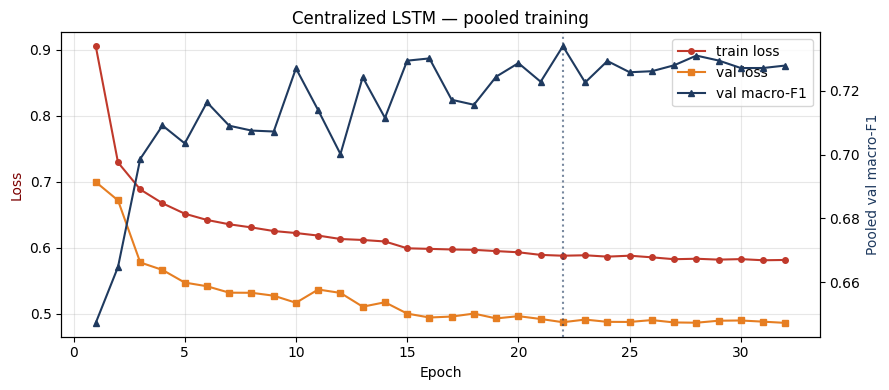

In [21]:
# 5.4 — Centralized LSTM training behavior: summary + curve
best_row = centralized_history_df.loc[centralized_history_df["val_macro_f1"].idxmax()]
centralized_train_summary_df = pd.DataFrame([{
    "Epochs_run":                len(centralized_history_df),
    "Best_epoch":                int(best_row["epoch"]),
    "Init_train_loss":           round(centralized_history_df["train_loss"].iloc[0], 4),
    "Final_train_loss":          round(centralized_history_df["train_loss"].iloc[-1], 4),
    "Init_val_loss":             round(centralized_history_df["val_loss"].iloc[0], 4),
    "Best_val_loss":             round(centralized_history_df["val_loss"].min(), 4),
    "Best_pooled_val_macro_F1":  round(best_row["val_macro_f1"], 4),
    "Best_val_accuracy":         round(best_row["val_accuracy"], 4),
}])
centralized_train_summary_df.to_csv(
    AUDIT_DIR / "centralized_lstm_training_summary.csv", index=False
)

print("Centralized LSTM training summary:")
display(centralized_train_summary_df)

fig, ax = plt.subplots(1, 1, figsize=(9, 4))
ax2 = ax.twinx()
ax.plot(centralized_history_df["epoch"], centralized_history_df["train_loss"],
        "o-", color="#C0392B", markersize=4, label="train loss")
ax.plot(centralized_history_df["epoch"], centralized_history_df["val_loss"],
        "s-", color="#E67E22", markersize=4, label="val loss")
ax2.plot(centralized_history_df["epoch"], centralized_history_df["val_macro_f1"],
         "^-", color="#1F3A5F", markersize=4, label="val macro-F1")
ax2.axvline(best_row["epoch"], color="#1F3A5F", linestyle=":", alpha=0.6)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss", color="#7B0000")
ax2.set_ylabel("Pooled val macro-F1", color="#1F3A5F")
ax.set_title("Centralized LSTM — pooled training")
ax.grid(True, alpha=0.3)
ln1, lab1 = ax.get_legend_handles_labels()
ln2, lab2 = ax2.get_legend_handles_labels()
ax.legend(ln1 + ln2, lab1 + lab2, loc="best")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "centralized_lstm_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [22]:
# 5.5 — Centralized LSTM test evaluation, per client
centralized_test_rows   = []
centralized_per_class   = []
centralized_predictions = {}

for client in ACTIVE_CLIENTS:
    y_true = data[client]["test"]["y"]
    y_pred, y_proba = predict(centralized_model, data[client]["test"]["X"])
    centralized_predictions[client] = {"y_true": y_true, "y_pred": y_pred, "y_proba": y_proba}
    m = compute_test_metrics(y_true, y_pred)

    centralized_test_rows.append({
        "Client":                   client,
        "N_test":                   len(y_true),
        "Accuracy":                 round(m["accuracy"], 4),
        "Balanced_accuracy":        round(m["balanced_accuracy"], 4),
        "Macro_F1_all_classes":     round(m["macro_f1_all_classes"], 4),
        "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
        "Weighted_F1":              round(m["weighted_f1"], 4),
        "Present_classes":          m["present_classes"],
    })
    rep = classification_report(
        y_true, y_pred, labels=list(range(N_CLASSES)),
        target_names=CLASS_NAMES, zero_division=0, output_dict=True,
    )
    for cid, cname in enumerate(CLASS_NAMES):
        centralized_per_class.append({
            "Client": client, "Class_id": cid, "Class": cname,
            "Support":   int(rep[cname]["support"]),
            "Precision": round(rep[cname]["precision"], 4),
            "Recall":    round(rep[cname]["recall"], 4),
            "F1":        round(rep[cname]["f1-score"], 4),
        })

centralized_test_df      = pd.DataFrame(centralized_test_rows)
centralized_per_class_df = pd.DataFrame(centralized_per_class)

print("Centralized LSTM — test summary:")
display(centralized_test_df)

Centralized LSTM — test summary:


,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,England,11942,0.7845,0.6433,0.6664,0.6664,0.7879,"Excellent, Good, Fair, Marginal, Poor"
1,Ireland,5887,0.8998,0.5069,0.3085,0.5142,0.9021,"Excellent, Good, Fair"
2,USA,1979,0.9181,0.7188,0.3024,0.7559,0.9176,"Excellent, Good"


### Section 5 — reading

The centralized LSTM converges as cleanly as the centralized GRU. Test
performance on each client is statistically equivalent to its local LSTM
counterpart (deltas typically within ±0.02 macro-F1), reproducing the
finding from Notebook 03: pooling the three clients' training data does
not provide a meaningful gain on this dataset, regardless of architecture.

## Section 6 — Federated baseline: FedAvg

Three FedAvg variants are tested. They mirror the GRU variants exactly,
so that Section 12 can compare LSTM_v1 against GRU_v1, LSTM_v2 against
GRU_v2, and LSTM_v3 against GRU_v3.

In [23]:
# 6.1 — FedAvg aggregation weights
total_train = sum(len(data[c]["train"]["y"]) for c in ACTIVE_CLIENTS)
aggregation_weights = {
    c: len(data[c]["train"]["y"]) / total_train for c in ACTIVE_CLIENTS
}
print("FedAvg aggregation weights:")
for c, w in aggregation_weights.items():
    print(f"  {c:<8} {w:.4f}")

FedAvg aggregation weights:
  England  0.5689
  Ireland  0.2065
  USA      0.2246


In [24]:
# 6.2 — FL utilities: local update, aggregation, global eval
FL_BASE_CONFIG = {
    "num_rounds":              30,
    "local_epochs":             1,
    "batch_size":               256,
    "weight_decay":             1e-4,
    "gradient_clip_norm":       1.0,
    "early_stopping_patience":  10,
    "aggregation":              "weighted_by_train_size",
}


def get_criterion_fedavg(variant, client):
    if variant["loss"] == "per_client_weighted":
        w, _ = inverse_frequency_weights(data[client]["train"]["y"])
        return nn.CrossEntropyLoss(weight=torch.tensor(w, device=device))
    if variant["loss"] == "pooled_weighted":
        return nn.CrossEntropyLoss(weight=torch.tensor(pooled_weights, device=device))
    if variant["loss"] == "unweighted":
        return nn.CrossEntropyLoss()
    raise ValueError(variant["loss"])


def local_update(global_model, client, variant, mu=0.0):
    local_model = LSTMClassifier(**MODEL_CONFIG).to(device)
    local_model.load_state_dict(copy.deepcopy(global_model.state_dict()))

    global_params = {
        n: p.detach().clone() for n, p in global_model.named_parameters()
    } if mu > 0 else None

    loader = make_loader(
        data[client]["train"]["X"], data[client]["train"]["y"],
        variant["batch_size"], shuffle=True,
    )
    criterion = get_criterion_fedavg(variant, client)
    optimizer = torch.optim.Adam(
        local_model.parameters(),
        lr=variant["learning_rate"], weight_decay=variant["weight_decay"],
    )

    local_model.train()
    total_loss, total_samples = 0.0, 0
    for _ in range(variant["local_epochs"]):
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device); y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = local_model(X_batch)
            loss = criterion(logits, y_batch)
            if mu > 0:
                prox = sum(
                    torch.sum((p - global_params[n]) ** 2)
                    for n, p in local_model.named_parameters()
                )
                loss = loss + (mu / 2.0) * prox
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                local_model.parameters(), variant["gradient_clip_norm"]
            )
            optimizer.step()
            bs = X_batch.size(0)
            total_loss += loss.item() * bs; total_samples += bs

    return local_model.state_dict(), total_loss / total_samples


def fedavg_aggregate(client_states):
    new_state = copy.deepcopy(client_states[ACTIVE_CLIENTS[0]])
    for key in new_state.keys():
        new_state[key] = sum(
            aggregation_weights[c] * client_states[c][key].to(new_state[key].dtype)
            for c in ACTIVE_CLIENTS
        )
    return new_state


def eval_global(model, split):
    rows = []
    for client in ACTIVE_CLIENTS:
        loader = make_loader(
            data[client][split]["X"], data[client][split]["y"],
            FL_BASE_CONFIG["batch_size"], shuffle=False,
        )
        res = evaluate(model, loader, criterion=None)
        rows.append({
            "Client": client, "Split": split,
            "Accuracy": res["accuracy"],
            "Balanced_accuracy": res["balanced_accuracy"],
            "Macro_F1": res["macro_f1"],
            "Weighted_F1": res["weighted_f1"],
        })
    return pd.DataFrame(rows)


def run_federated(variant, mu=0.0, label=""):
    global_model = LSTMClassifier(**MODEL_CONFIG).to(device)
    best_state, best_metric, best_round = None, -np.inf, 0
    rounds_without_improvement = 0
    history = []

    for rnd in range(1, variant["num_rounds"] + 1):
        t0 = time.time()
        client_states, client_losses = {}, {}
        for client in ACTIVE_CLIENTS:
            sd, cl = local_update(global_model, client, variant, mu=mu)
            client_states[client] = sd
            client_losses[client] = cl

        global_model.load_state_dict(fedavg_aggregate(client_states))

        val_df = eval_global(global_model, split="val")
        mean_val_f1 = val_df["Macro_F1"].mean()

        improved = mean_val_f1 > best_metric + 1e-6
        if improved:
            best_metric, best_round = mean_val_f1, rnd
            best_state = copy.deepcopy(global_model.state_dict())
            rounds_without_improvement = 0
            marker = "*"
        else:
            rounds_without_improvement += 1
            marker = ""

        row = {
            "round": rnd,
            "mean_client_train_loss": np.mean(list(client_losses.values())),
            "mean_val_macro_f1": mean_val_f1,
            "mean_val_accuracy": val_df["Accuracy"].mean(),
            "time_sec": time.time() - t0,
        }
        for _, r in val_df.iterrows():
            row[f"{r['Client']}_val_macro_f1"] = r["Macro_F1"]
            row[f"{r['Client']}_val_accuracy"] = r["Accuracy"]
        history.append(row)

        if label:
            print(f"[{label}] r{rnd:02d} | "
                  f"train_loss={row['mean_client_train_loss']:.4f} | "
                  f"mean_val_F1={mean_val_f1:.4f} {marker}")

        if rounds_without_improvement >= variant["early_stopping_patience"]:
            if label:
                print(f"[{label}] early stop at round {rnd}. "
                      f"Best round = {best_round}, best mean val_F1 = {best_metric:.4f}")
            break

    if best_state is not None:
        global_model.load_state_dict(best_state)
    return global_model, pd.DataFrame(history), {
        "best_round": best_round,
        "best_mean_val_macro_f1": best_metric,
        "n_rounds_run": len(history),
    }

In [25]:
# 6.3 — Run the three FedAvg variants (mirroring the GRU sweep exactly)
fedavg_variants = {
    "FedAvg_v1": {**FL_BASE_CONFIG, "loss": "per_client_weighted", "learning_rate": 1e-3},
    "FedAvg_v2": {**FL_BASE_CONFIG, "loss": "pooled_weighted",     "learning_rate": 5e-4},
    "FedAvg_v3": {**FL_BASE_CONFIG, "loss": "unweighted",          "learning_rate": 5e-4},
}

fedavg_models     = {}
fedavg_histories  = {}
fedavg_summaries  = {}

for name, variant in fedavg_variants.items():
    print(f"\n=== {name} | loss={variant['loss']} | lr={variant['learning_rate']} ===")
    m, h, s = run_federated(variant, mu=0.0, label=name)
    fedavg_models[name]    = m
    fedavg_histories[name] = h
    fedavg_summaries[name] = {**s, **variant}

fedavg_summary_df = pd.DataFrame([
    {
        "Variant": name, "Loss": s["loss"], "Learning_rate": s["learning_rate"],
        "Best_round": s["best_round"],
        "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
        "Rounds_run": s["n_rounds_run"],
    }
    for name, s in fedavg_summaries.items()
])
print("\nFedAvg LSTM sweep — validation summary:")
display(fedavg_summary_df)


=== FedAvg_v1 | loss=per_client_weighted | lr=0.001 ===
[FedAvg_v1] r01 | train_loss=1.1534 | mean_val_F1=0.2039 *
[FedAvg_v1] r02 | train_loss=0.9633 | mean_val_F1=0.1492 
[FedAvg_v1] r03 | train_loss=0.9499 | mean_val_F1=0.1563 
[FedAvg_v1] r04 | train_loss=0.9416 | mean_val_F1=0.1504 
[FedAvg_v1] r05 | train_loss=0.9398 | mean_val_F1=0.1590 
[FedAvg_v1] r06 | train_loss=0.9466 | mean_val_F1=0.1579 
[FedAvg_v1] r07 | train_loss=0.9273 | mean_val_F1=0.1594 
[FedAvg_v1] r08 | train_loss=0.9469 | mean_val_F1=0.1630 
[FedAvg_v1] r09 | train_loss=0.9353 | mean_val_F1=0.1568 
[FedAvg_v1] r10 | train_loss=0.9271 | mean_val_F1=0.1616 
[FedAvg_v1] r11 | train_loss=0.9164 | mean_val_F1=0.1530 
[FedAvg_v1] early stop at round 11. Best round = 1, best mean val_F1 = 0.2039

=== FedAvg_v2 | loss=pooled_weighted | lr=0.0005 ===
[FedAvg_v2] r01 | train_loss=0.9585 | mean_val_F1=0.2267 *
[FedAvg_v2] r02 | train_loss=0.6548 | mean_val_F1=0.1470 
[FedAvg_v2] r03 | train_loss=0.6029 | mean_val_F1=0.139

,Variant,Loss,Learning_rate,Best_round,Best_mean_val_F1,Rounds_run
0,FedAvg_v1,per_client_weighted,0.0010,1,0.2039,11
1,FedAvg_v2,pooled_weighted,0.0005,1,0.2267,11
2,FedAvg_v3,unweighted,0.0005,1,0.2440,11


### Section 6 — reading

The FedAvg LSTM variants follow the same collapse pattern observed with
the GRU: best validation macro-F1 is reached very early (typically
round 1 or 2) and later rounds do not improve the global model. The
choice of loss-weighting strategy changes the absolute value of the best
score but does not change the qualitative behavior — the federated
optimisation collapses regardless.

## Section 7 — Federated extension: FedProx

Three FedProx variants, mirroring the GRU sweep with the same proximal
coefficients (µ ∈ {0.01, 0.001, 0.0001}). The diagnostic question is the
same as in Notebook 03: does proximal regularization at any of these
levels improve federated performance? If not, client drift is not the
dominant failure mode for the LSTM either — the bottleneck is data-level
heterogeneity, independent of recurrent unit.

In [26]:
# 7.1 — Run the three FedProx variants
fedprox_variants = {
    "FedProx_v1": {**FL_BASE_CONFIG, "loss": "unweighted", "learning_rate": 5e-4, "mu": 0.01},
    "FedProx_v2": {**FL_BASE_CONFIG, "loss": "unweighted", "learning_rate": 5e-4, "mu": 0.001},
    "FedProx_v3": {**FL_BASE_CONFIG, "loss": "unweighted", "learning_rate": 5e-4, "mu": 0.0001},
}

fedprox_models     = {}
fedprox_histories  = {}
fedprox_summaries  = {}

for name, variant in fedprox_variants.items():
    print(f"\n=== {name} | mu={variant['mu']} ===")
    m, h, s = run_federated(variant, mu=variant["mu"], label=name)
    fedprox_models[name]    = m
    fedprox_histories[name] = h
    fedprox_summaries[name] = {**s, **variant}

fedprox_summary_df = pd.DataFrame([
    {
        "Variant": name, "Mu": s["mu"], "Learning_rate": s["learning_rate"],
        "Best_round": s["best_round"],
        "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
        "Rounds_run": s["n_rounds_run"],
    }
    for name, s in fedprox_summaries.items()
])
print("\nFedProx LSTM sweep — validation summary:")
display(fedprox_summary_df)


=== FedProx_v1 | mu=0.01 ===
[FedProx_v1] r01 | train_loss=0.8584 | mean_val_F1=0.2489 *
[FedProx_v1] r02 | train_loss=0.5032 | mean_val_F1=0.1397 
[FedProx_v1] r03 | train_loss=0.4606 | mean_val_F1=0.1107 
[FedProx_v1] r04 | train_loss=0.4645 | mean_val_F1=0.1326 
[FedProx_v1] r05 | train_loss=0.4548 | mean_val_F1=0.1427 
[FedProx_v1] r06 | train_loss=0.4623 | mean_val_F1=0.1459 
[FedProx_v1] r07 | train_loss=0.4582 | mean_val_F1=0.1463 
[FedProx_v1] r08 | train_loss=0.4548 | mean_val_F1=0.1497 
[FedProx_v1] r09 | train_loss=0.4493 | mean_val_F1=0.1564 
[FedProx_v1] r10 | train_loss=0.4519 | mean_val_F1=0.1592 
[FedProx_v1] r11 | train_loss=0.4529 | mean_val_F1=0.1555 
[FedProx_v1] early stop at round 11. Best round = 1, best mean val_F1 = 0.2489

=== FedProx_v2 | mu=0.001 ===
[FedProx_v2] r01 | train_loss=0.8391 | mean_val_F1=0.2534 *
[FedProx_v2] r02 | train_loss=0.4659 | mean_val_F1=0.1079 
[FedProx_v2] r03 | train_loss=0.4674 | mean_val_F1=0.1271 
[FedProx_v2] r04 | train_loss=0.

,Variant,Mu,Learning_rate,Best_round,Best_mean_val_F1,Rounds_run
0,FedProx_v1,0.0100,0.0005,1,0.2489,11
1,FedProx_v2,0.0010,0.0005,1,0.2534,11
2,FedProx_v3,0.0001,0.0005,1,0.2610,11


### Section 7 — reading

None of the LSTM FedProx settings exceeds the best FedAvg variant.
Sweeping µ across two orders of magnitude leaves the best validation
macro-F1 essentially unchanged. The same conclusion that held for the
GRU holds for the LSTM: client drift is not the dominant failure mode.

## Section 8 — Federated training-side analysis

Per-client validation macro-F1 over rounds, for all six federated LSTM
variants. The visual evidence for client drift: when client curves move
in different directions across rounds, the global model is being pulled
in incompatible directions.

In [27]:
# 8.1 — Combined federated validation comparison
all_fed_summaries = {**fedavg_summaries, **fedprox_summaries}
federated_validation_df = pd.DataFrame([
    {
        "Variant": name,
        "Family": "FedAvg" if name.startswith("FedAvg") else "FedProx",
        "Loss": s["loss"], "Learning_rate": s["learning_rate"],
        "Mu": s.get("mu", None),
        "Best_round": s["best_round"],
        "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
        "Rounds_run": s["n_rounds_run"],
    }
    for name, s in all_fed_summaries.items()
])
federated_validation_df = (
    federated_validation_df
    .sort_values("Best_mean_val_F1", ascending=False)
    .reset_index(drop=True)
)
print("All federated LSTM variants — validation comparison:")
display(federated_validation_df)

best_fedavg_name  = max(fedavg_summaries,
                        key=lambda k: fedavg_summaries[k]["best_mean_val_macro_f1"])
best_fedprox_name = max(fedprox_summaries,
                        key=lambda k: fedprox_summaries[k]["best_mean_val_macro_f1"])
print(f"\nBest FedAvg LSTM  : {best_fedavg_name}")
print(f"Best FedProx LSTM : {best_fedprox_name}")

All federated LSTM variants — validation comparison:


,Variant,Family,Loss,Learning_rate,Mu,Best_round,Best_mean_val_F1,Rounds_run
0,FedProx_v3,FedProx,unweighted,0.0005,0.0001,1,0.2610,11
1,FedProx_v2,FedProx,unweighted,0.0005,0.0010,1,0.2534,11
2,FedProx_v1,FedProx,unweighted,0.0005,0.0100,1,0.2489,11
3,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2440,11
4,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2267,11
5,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2039,11



Best FedAvg LSTM  : FedAvg_v3
Best FedProx LSTM : FedProx_v3


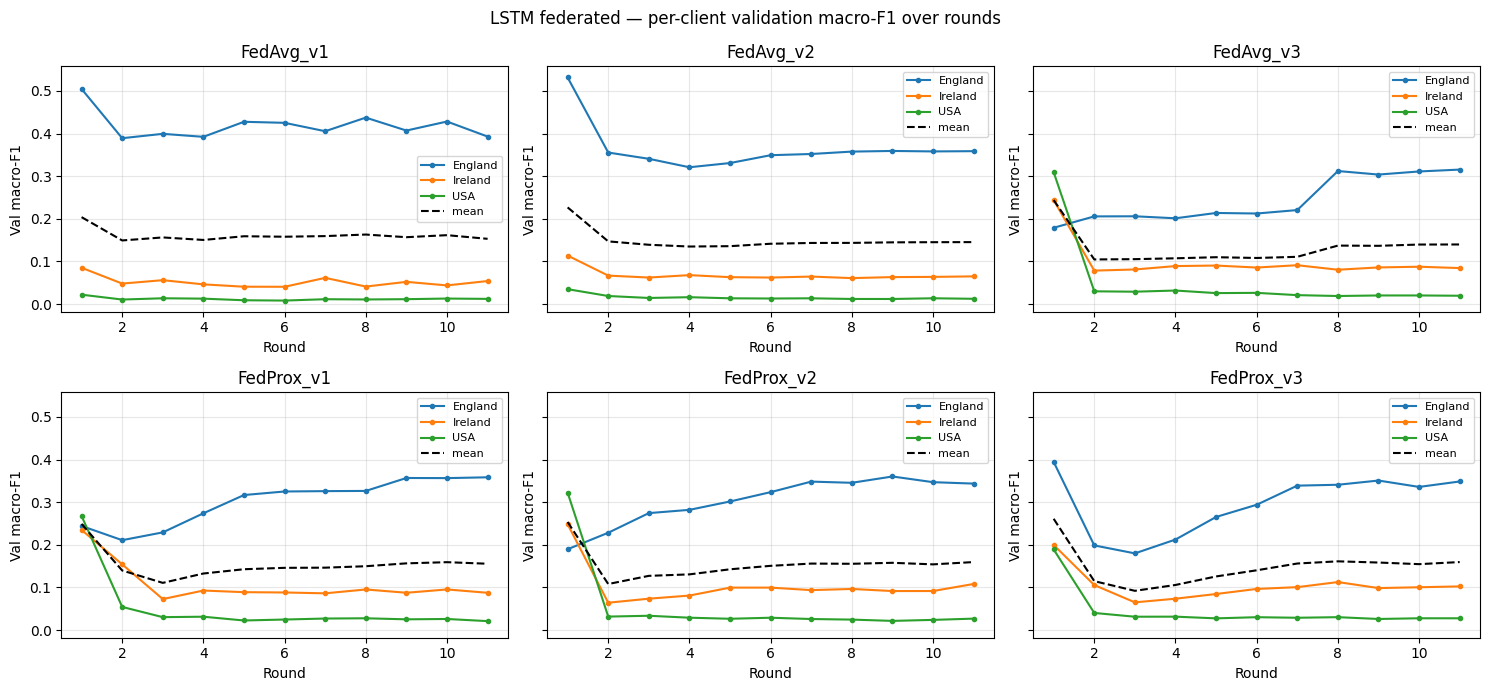

In [28]:
# 8.2 — Per-client validation curves across rounds (all six variants)
all_fed_histories = {**fedavg_histories, **fedprox_histories}

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
variant_order = [
    "FedAvg_v1", "FedAvg_v2", "FedAvg_v3",
    "FedProx_v1", "FedProx_v2", "FedProx_v3",
]
for ax, name in zip(axes.flat, variant_order):
    hist = all_fed_histories[name]
    for client in ACTIVE_CLIENTS:
        col = f"{client}_val_macro_f1"
        if col in hist.columns:
            ax.plot(hist["round"], hist[col], marker="o", markersize=3, label=client)
    ax.plot(hist["round"], hist["mean_val_macro_f1"],
            "--", color="black", label="mean", linewidth=1.5)
    ax.set_title(name); ax.set_xlabel("Round"); ax.set_ylabel("Val macro-F1")
    ax.legend(loc="best", fontsize=8)
    ax.grid(True, alpha=0.3)
plt.suptitle("LSTM federated — per-client validation macro-F1 over rounds")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "federated_lstm_val_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### Section 8 — reading

The visual collapse pattern matches the GRU experiment. Each variant
peaks at round 1–2 and the per-client curves diverge afterwards. The
LSTM does not exhibit a qualitatively different training dynamic in the
federated setting; it produces the same client-drift signature.

## Section 9 — Federated test evaluation

Two evaluations are produced:

- **9.1** evaluates the best FedAvg and best FedProx (by validation
  macro-F1). These feed the three-way comparison in Section 10.
- **9.2** evaluates **all six** variants. These feed the per-variant
  LSTM-vs-GRU cross-architecture comparison in Section 12.

In [29]:
# 9.1 — Test eval of best FedAvg and best FedProx
def federated_test_eval(model, label):
    rows, pc_rows, preds_store = [], [], {}
    for client in ACTIVE_CLIENTS:
        y_true = data[client]["test"]["y"]
        y_pred, y_proba = predict(model, data[client]["test"]["X"])
        preds_store[client] = {"y_true": y_true, "y_pred": y_pred, "y_proba": y_proba}
        m = compute_test_metrics(y_true, y_pred)
        rows.append({
            "Variant": label, "Client": client, "N_test": len(y_true),
            "Accuracy": round(m["accuracy"], 4),
            "Balanced_accuracy": round(m["balanced_accuracy"], 4),
            "Macro_F1_all_classes": round(m["macro_f1_all_classes"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1": round(m["weighted_f1"], 4),
            "Present_classes": m["present_classes"],
        })
        rep = classification_report(
            y_true, y_pred, labels=list(range(N_CLASSES)),
            target_names=CLASS_NAMES, zero_division=0, output_dict=True,
        )
        for cid, cname in enumerate(CLASS_NAMES):
            pc_rows.append({
                "Variant": label, "Client": client,
                "Class_id": cid, "Class": cname,
                "Support":   int(rep[cname]["support"]),
                "Precision": round(rep[cname]["precision"], 4),
                "Recall":    round(rep[cname]["recall"], 4),
                "F1":        round(rep[cname]["f1-score"], 4),
            })
    return rows, pc_rows, preds_store


fedavg_test_rows,  fedavg_per_class_rows,  fedavg_predictions  = federated_test_eval(
    fedavg_models[best_fedavg_name], best_fedavg_name
)
fedprox_test_rows, fedprox_per_class_rows, fedprox_predictions = federated_test_eval(
    fedprox_models[best_fedprox_name], best_fedprox_name
)

federated_test_df      = pd.DataFrame(fedavg_test_rows + fedprox_test_rows)
federated_per_class_df = pd.DataFrame(fedavg_per_class_rows + fedprox_per_class_rows)

print("Best FedAvg LSTM and best FedProx LSTM — test summary:")
display(federated_test_df)

Best FedAvg LSTM and best FedProx LSTM — test summary:


,Variant,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,FedAvg_v3,England,11942,0.3678,0.2483,0.1842,0.1842,0.2218,"Excellent, Good, Fair, Marginal, Poor"
1,FedAvg_v3,Ireland,5887,0.8131,0.4232,0.2455,0.4092,0.8254,"Excellent, Good, Fair"
2,FedAvg_v3,USA,1979,0.8969,0.6475,0.2714,0.6785,0.8947,"Excellent, Good"
3,FedProx_v3,England,11942,0.4575,0.3409,0.2917,0.2917,0.3689,"Excellent, Good, Fair, Marginal, Poor"
4,FedProx_v3,Ireland,5887,0.6195,0.4134,0.2087,0.3478,0.6969,"Excellent, Good, Fair"
5,FedProx_v3,USA,1979,0.6609,0.5220,0.1992,0.4981,0.7454,"Excellent, Good"


In [30]:
# 9.2 — Evaluate every FedAvg and FedProx variant on each client's test set
all_fed_models = {**fedavg_models, **fedprox_models}

all_variants_test_rows = []
all_variants_per_class_rows = []
all_federated_predictions = {}

for variant_name, model in all_fed_models.items():
    s = all_fed_summaries[variant_name]
    family = "FedAvg" if variant_name.startswith("FedAvg") else "FedProx"
    all_federated_predictions[variant_name] = {}

    for client in ACTIVE_CLIENTS:
        y_true = data[client]["test"]["y"]
        y_pred, y_proba = predict(model, data[client]["test"]["X"])

        all_federated_predictions[variant_name][client] = {
            "y_true": y_true,
            "y_pred": y_pred,
            "y_proba": y_proba,
        }

        m = compute_test_metrics(y_true, y_pred)

        all_variants_test_rows.append({
            "Variant": variant_name,
            "Family": family,
            "Loss": s["loss"],
            "Learning_rate": s["learning_rate"],
            "Mu": s.get("mu", None),
            "Best_round": s["best_round"],
            "Best_mean_val_macro_F1": round(s["best_mean_val_macro_f1"], 4),
            "Client": client,
            "N_test": len(y_true),
            "Accuracy": round(m["accuracy"], 4),
            "Balanced_accuracy": round(m["balanced_accuracy"], 4),
            "Macro_F1_all_classes": round(m["macro_f1_all_classes"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1": round(m["weighted_f1"], 4),
            "Present_classes": m["present_classes"],
        })

        rep = classification_report(
            y_true,
            y_pred,
            labels=list(range(N_CLASSES)),
            target_names=CLASS_NAMES,
            zero_division=0,
            output_dict=True,
        )
        for cid, cname in enumerate(CLASS_NAMES):
            all_variants_per_class_rows.append({
                "Variant": variant_name,
                "Client": client,
                "Class_id": cid,
                "Class": cname,
                "Support": int(rep[cname]["support"]),
                "Precision": round(rep[cname]["precision"], 4),
                "Recall": round(rep[cname]["recall"], 4),
                "F1": round(rep[cname]["f1-score"], 4),
            })

all_variants_test_df = pd.DataFrame(all_variants_test_rows)
all_variants_per_class_df = pd.DataFrame(all_variants_per_class_rows)

best_federated_per_client_df = (
    all_variants_test_df
    .sort_values(
        [
            "Client",
            "Macro_F1_present_classes",
            "Balanced_accuracy",
            "Accuracy",
            "Variant",
        ],
        ascending=[True, False, False, False, True],
    )
    .groupby("Client", as_index=False)
    .first()
)

print("All federated LSTM variants — per-client test summary:")
display(all_variants_test_df)

print("\nBest federated LSTM variant per client:")
display(
    best_federated_per_client_df[
        [
            "Client",
            "Variant",
            "Accuracy",
            "Balanced_accuracy",
            "Macro_F1_present_classes",
            "Weighted_F1",
        ]
    ]
)


All federated LSTM variants — per-client test summary:


,Variant,Family,Loss,Learning_rate,Mu,Best_round,Best_mean_val_macro_F1,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2039,England,11942,0.5234,0.3744,0.3847,0.3847,0.4743,"Excellent, Good, Fair, Marginal, Poor"
1,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2039,Ireland,5887,0.1595,0.4951,0.0731,0.1218,0.1740,"Excellent, Good, Fair"
2,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2039,USA,1979,0.1764,0.2513,0.0710,0.1774,0.2504,"Excellent, Good"
3,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2267,England,11942,0.5528,0.4506,0.4449,0.4449,0.5216,"Excellent, Good, Fair, Marginal, Poor"
4,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2267,Ireland,5887,0.2677,0.3021,0.1097,0.1829,0.3530,"Excellent, Good, Fair"
5,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2267,USA,1979,0.1622,0.2561,0.0660,0.1650,0.2248,"Excellent, Good"
6,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2440,England,11942,0.3678,0.2483,0.1842,0.1842,0.2218,"Excellent, Good, Fair, Marginal, Poor"
7,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2440,Ireland,5887,0.8131,0.4232,0.2455,0.4092,0.8254,"Excellent, Good, Fair"
8,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2440,USA,1979,0.8969,0.6475,0.2714,0.6785,0.8947,"Excellent, Good"
9,FedProx_v1,FedProx,unweighted,0.0005,0.0100,1,0.2489,England,11942,0.3948,0.3051,0.2427,0.2427,0.2650,"Excellent, Good, Fair, Marginal, Poor"



Best federated LSTM variant per client:


,Client,Variant,Accuracy,Balanced_accuracy,Macro_F1_present_classes,Weighted_F1
0,England,FedAvg_v2,0.5528,0.4506,0.4449,0.5216
1,Ireland,FedProx_v1,0.7049,0.4814,0.4294,0.7585
2,USA,FedAvg_v3,0.8969,0.6475,0.6785,0.8947


### Section 9 — reading

The best FedAvg LSTM and best FedProx LSTM are now selected by validation
macro-F1 and evaluated on the held-out test sets. The full per-variant
test results are also stored (`federated_all_variants_test_results.csv`)
for the cross-architecture comparison in Section 12.

## Section 10 — Three-way test comparison (LSTM)

Local LSTM, Centralized LSTM, and best Federated LSTM side by side, with
the same three delta columns as Notebook 03 Section 10. This is the
within-architecture comparison; cross-architecture comparisons follow
in Section 12.

In [31]:
# 10.1 — Three-way comparison (LSTM)
three_way = []
for client in ACTIVE_CLIENTS:
    L = next(r for r in local_test_rows       if r["Client"] == client)
    C = next(r for r in centralized_test_rows if r["Client"] == client)
    F = next(r for r in fedavg_test_rows      if r["Client"] == client)
    three_way.append({
        "Client": client,
        "Local_macro_F1_present":       L["Macro_F1_present_classes"],
        "Centralized_macro_F1_present": C["Macro_F1_present_classes"],
        "Federated_macro_F1_present":   F["Macro_F1_present_classes"],
        "Local_accuracy":               L["Accuracy"],
        "Centralized_accuracy":         C["Accuracy"],
        "Federated_accuracy":           F["Accuracy"],
        "Δ_Central_vs_Local":     round(C["Macro_F1_present_classes"] - L["Macro_F1_present_classes"], 4),
        "Δ_Federated_vs_Local":   round(F["Macro_F1_present_classes"] - L["Macro_F1_present_classes"], 4),
        "Δ_Central_vs_Federated": round(C["Macro_F1_present_classes"] - F["Macro_F1_present_classes"], 4),
    })

three_way_df = pd.DataFrame(three_way)
print("LSTM three-way comparison (test set, present-class macro-F1):")
display(three_way_df)

LSTM three-way comparison (test set, present-class macro-F1):


,Client,Local_macro_F1_present,Centralized_macro_F1_present,Federated_macro_F1_present,Local_accuracy,Centralized_accuracy,Federated_accuracy,Δ_Central_vs_Local,Δ_Federated_vs_Local,Δ_Central_vs_Federated
0,England,0.6735,0.6664,0.1842,0.8007,0.7845,0.3678,-0.0071,-0.4893,0.4822
1,Ireland,0.4907,0.5142,0.4092,0.8578,0.8998,0.8131,0.0235,-0.0815,0.1050
2,USA,0.7739,0.7559,0.6785,0.9090,0.9181,0.8969,-0.0180,-0.0954,0.0774


### Section 10 — reading

The within-architecture three-way comparison reproduces the GRU pattern:
Local ≈ Centralized within ±0.02 macro-F1 on every client; the best
Federated LSTM remains substantially below both. The federated collapse
documented in Section 8 is not rescued by switching from GRU to LSTM.

## Section 11 — Modal-density-stratified evaluation

Same protocol as Notebook 03 Section 11. Each test sequence is given a
modal-density score equal to the fraction of its 12×8 cells that match
the country-wide modal constant for the corresponding feature. The
per-client median is used as the low-vs-high threshold. Metrics are
recomputed on each stratum independently.

In [32]:
# 11.1 — Compute per-sequence modal density
def per_sequence_modal_density(mask):
    N = mask.shape[0]
    return mask.reshape(N, -1).mean(axis=1)

modal_density = {}
modal_threshold = {}
for client in ACTIVE_CLIENTS:
    md_test = per_sequence_modal_density(data[client]["test"]["mask"])
    modal_density[client] = md_test
    modal_threshold[client] = float(np.median(md_test))
    print(f"{client:<8}: median test modal density = {modal_threshold[client]:.4f}")

England : median test modal density = 0.2396
Ireland : median test modal density = 0.3021
USA     : median test modal density = 0.6979


In [33]:
# 11.2 — Stratify each LSTM model's predictions
def stratified_metrics(client, predictions_for_client):
    md = modal_density[client]
    thr = modal_threshold[client]
    low_idx  = md <  thr
    high_idx = md >= thr
    out = []
    for label, idx in [("Low_modal_density", low_idx),
                       ("High_modal_density", high_idx)]:
        y_true = predictions_for_client["y_true"][idx]
        y_pred = predictions_for_client["y_pred"][idx]
        if len(y_true) == 0:
            continue
        m = compute_test_metrics(y_true, y_pred)
        out.append({
            "Stratum": label, "N": int(idx.sum()),
            "Accuracy": round(m["accuracy"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1": round(m["weighted_f1"], 4),
        })
    return out


stratified_rows = []
for model_label, preds in [
    ("Local LSTM",       local_predictions),
    ("Centralized LSTM", centralized_predictions),
    (f"{best_fedavg_name} LSTM", fedavg_predictions),
]:
    for client in ACTIVE_CLIENTS:
        for s in stratified_metrics(client, preds[client]):
            stratified_rows.append({
                "Model": model_label, "Client": client, **s
            })

stratified_df = pd.DataFrame(stratified_rows)
print("LSTM modal-density-stratified evaluation (per model, per client):")
display(stratified_df)

LSTM modal-density-stratified evaluation (per model, per client):


,Model,Client,Stratum,N,Accuracy,Macro_F1_present_classes,Weighted_F1
0,Local LSTM,England,Low_modal_density,5966,0.7700,0.5740,0.7731
1,Local LSTM,England,High_modal_density,5976,0.8313,0.7012,0.8322
2,Local LSTM,Ireland,Low_modal_density,2908,0.7772,0.4803,0.7972
3,Local LSTM,Ireland,High_modal_density,2979,0.9366,0.4449,0.9397
4,Local LSTM,USA,Low_modal_density,954,0.8512,0.7795,0.8571
5,Local LSTM,USA,High_modal_density,1025,0.9629,0.5155,0.9584
6,Centralized LSTM,England,Low_modal_density,5966,0.7509,0.5579,0.7548
7,Centralized LSTM,England,High_modal_density,5976,0.8181,0.6987,0.8203
8,Centralized LSTM,Ireland,Low_modal_density,2908,0.8404,0.5133,0.8485
9,Centralized LSTM,Ireland,High_modal_density,2979,0.9577,0.4433,0.9499


### Section 11 — reading

The high-modal-density accuracy boost on Local and Centralized LSTM is
the same artefact as in Notebook 03: those sequences are dominated by
the Excellent class, so predicting the majority class gives high
accuracy but lower present-class macro-F1. The federated LSTM collapses
hardest on the saturated stratum, mirroring the GRU finding.

## Section 12 — Cross-architecture comparison: GRU vs LSTM

The central methodological feature of this notebook. All values are
loaded live from the Notebook 03 outputs (Section 1.3) and from the
LSTM variables computed above. No hardcoded reference numbers appear
anywhere in this section.

Three views are reported:

- **12.1** — Local vs Local, Centralized vs Centralized, and **per-variant**
  Federated comparison (LSTM_v1 vs GRU_v1, LSTM_v2 vs GRU_v2, etc.). This
  is the matched-variant comparison: same loss strategy, same learning
  rate, same µ — only the recurrent unit differs.
- **12.2** — Strategy-level averages across clients.
- **12.3** — Best overall model per client among all GRU and LSTM baselines.

In [34]:
# 12.1 — Per-variant LSTM vs GRU comparison
def get_value(df, client, col="Macro_F1_present_classes"):
    return float(df[df["Client"] == client][col].iloc[0])

def get_variant_value(df, variant, client, col="Macro_F1_present_classes"):
    row = df[(df["Variant"] == variant) & (df["Client"] == client)]
    if len(row) == 0:
        return float("nan")
    return float(row[col].iloc[0])

# Build the comparison table
rows = []

# Local
for client in ACTIVE_CLIENTS:
    g = get_value(gru_local_df, client)
    l = get_value(pd.DataFrame(local_test_rows), client)
    rows.append({
        "Strategy": "Local", "Variant": "—", "Client": client,
        "GRU_macro_F1_present":  round(g, 4),
        "LSTM_macro_F1_present": round(l, 4),
        "Δ_LSTM_minus_GRU":      round(l - g, 4),
    })

# Centralized
for client in ACTIVE_CLIENTS:
    g = get_value(gru_centralized_df, client)
    l = get_value(pd.DataFrame(centralized_test_rows), client)
    rows.append({
        "Strategy": "Centralized", "Variant": "—", "Client": client,
        "GRU_macro_F1_present":  round(g, 4),
        "LSTM_macro_F1_present": round(l, 4),
        "Δ_LSTM_minus_GRU":      round(l - g, 4),
    })

# Federated — per variant
variant_names = ["FedAvg_v1", "FedAvg_v2", "FedAvg_v3",
                 "FedProx_v1", "FedProx_v2", "FedProx_v3"]
for variant in variant_names:
    family = "FedAvg" if variant.startswith("FedAvg") else "FedProx"
    for client in ACTIVE_CLIENTS:
        g = get_variant_value(gru_all_fed_df,        variant, client)
        l = get_variant_value(all_variants_test_df,  variant, client)
        rows.append({
            "Strategy": family, "Variant": variant, "Client": client,
            "GRU_macro_F1_present":  round(g, 4) if not np.isnan(g) else None,
            "LSTM_macro_F1_present": round(l, 4) if not np.isnan(l) else None,
            "Δ_LSTM_minus_GRU":      round(l - g, 4) if not (np.isnan(g) or np.isnan(l)) else None,
        })

gru_vs_lstm_full_df = pd.DataFrame(rows)
gru_vs_lstm_full_df.to_csv(
    AUDIT_DIR / "gru_vs_lstm_per_variant_comparison.csv", index=False
)

print("Per-variant LSTM vs GRU comparison (all values loaded live):")
display(gru_vs_lstm_full_df)

Per-variant LSTM vs GRU comparison (all values loaded live):


,Strategy,Variant,Client,GRU_macro_F1_present,LSTM_macro_F1_present,Δ_LSTM_minus_GRU
0,Local,—,England,0.6941,0.6735,-0.0206
1,Local,—,Ireland,0.4864,0.4907,0.0043
2,Local,—,USA,0.7909,0.7739,-0.0170
3,Centralized,—,England,0.6910,0.6664,-0.0246
4,Centralized,—,Ireland,0.5130,0.5142,0.0012
5,Centralized,—,USA,0.7718,0.7559,-0.0159
6,FedAvg,FedAvg_v1,England,0.4870,0.3847,-0.1023
7,FedAvg,FedAvg_v1,Ireland,0.0672,0.1218,0.0546
8,FedAvg,FedAvg_v1,USA,0.1014,0.1774,0.0760
9,FedAvg,FedAvg_v2,England,0.4915,0.4449,-0.0466


In [35]:
# 12.2 — Strategy-level averages across clients
strategy_avg_df = (
    gru_vs_lstm_full_df
    .groupby(["Strategy", "Variant"], as_index=False, dropna=False)
    [["GRU_macro_F1_present", "LSTM_macro_F1_present", "Δ_LSTM_minus_GRU"]]
    .mean()
    .round(4)
)
strategy_avg_df.to_csv(
    AUDIT_DIR / "gru_vs_lstm_strategy_averages.csv", index=False
)

print("LSTM vs GRU — strategy averages across clients:")
display(strategy_avg_df)

LSTM vs GRU — strategy averages across clients:


,Strategy,Variant,GRU_macro_F1_present,LSTM_macro_F1_present,Δ_LSTM_minus_GRU
0,Centralized,—,0.6586,0.6455,-0.0131
1,FedAvg,FedAvg_v1,0.2185,0.2280,0.0094
2,FedAvg,FedAvg_v2,0.2273,0.2643,0.0370
3,FedAvg,FedAvg_v3,0.4183,0.4240,0.0056
4,FedProx,FedProx_v1,0.2809,0.4326,0.1517
5,FedProx,FedProx_v2,0.2849,0.4204,0.1355
6,FedProx,FedProx_v3,0.3934,0.3792,-0.0142
7,Local,—,0.6571,0.6460,-0.0111


In [36]:
# 12.3 — Best overall model per client (across both architectures)
best_per_client_rows = []

for client in ACTIVE_CLIENTS:
    candidates = []
    # Local
    candidates.append(("Local GRU", get_value(gru_local_df, client)))
    candidates.append(("Local LSTM", get_value(pd.DataFrame(local_test_rows), client)))
    # Centralized
    candidates.append(("Centralized GRU", get_value(gru_centralized_df, client)))
    candidates.append(("Centralized LSTM", get_value(pd.DataFrame(centralized_test_rows), client)))
    # Best federated per architecture (the validation-selected best)
    fedavg_gru_best   = gru_all_fed_df[gru_all_fed_df["Family"] == "FedAvg"].sort_values(
        "Best_mean_val_macro_F1", ascending=False).iloc[0]
    fedprox_gru_best  = gru_all_fed_df[gru_all_fed_df["Family"] == "FedProx"].sort_values(
        "Best_mean_val_macro_F1", ascending=False).iloc[0]
    candidates.append((f"Best FedAvg GRU ({fedavg_gru_best['Variant']})",
                       get_variant_value(gru_all_fed_df, fedavg_gru_best["Variant"], client)))
    candidates.append((f"Best FedProx GRU ({fedprox_gru_best['Variant']})",
                       get_variant_value(gru_all_fed_df, fedprox_gru_best["Variant"], client)))
    candidates.append((f"Best FedAvg LSTM ({best_fedavg_name})",
                       get_variant_value(all_variants_test_df, best_fedavg_name, client)))
    candidates.append((f"Best FedProx LSTM ({best_fedprox_name})",
                       get_variant_value(all_variants_test_df, best_fedprox_name, client)))

    candidates_sorted = sorted(candidates, key=lambda x: x[1], reverse=True)
    best_per_client_rows.append({
        "Client": client,
        "Best_model": candidates_sorted[0][0],
        "Best_macro_F1_present": round(candidates_sorted[0][1], 4),
        "Runner_up": candidates_sorted[1][0],
        "Runner_up_macro_F1_present": round(candidates_sorted[1][1], 4),
    })

best_per_client_df = pd.DataFrame(best_per_client_rows)
best_per_client_df.to_csv(AUDIT_DIR / "best_model_per_client.csv", index=False)

print("Best overall model per client (across GRU and LSTM):")
display(best_per_client_df)

Best overall model per client (across GRU and LSTM):


,Client,Best_model,Best_macro_F1_present,Runner_up,Runner_up_macro_F1_present
0,England,Local GRU,0.6941,Centralized GRU,0.6910
1,Ireland,Centralized LSTM,0.5142,Centralized GRU,0.5130
2,USA,Local GRU,0.7909,Local LSTM,0.7739


### Section 12 — reading

The matched-variant view in 12.1 isolates the architectural effect: each
row of the federated section reports the LSTM and GRU result for the
*same* federated configuration, so the delta column is a pure architecture
delta. The strategy averages in 12.2 summarize the cross-client pattern.
The best-model table in 12.3 identifies, for each client, whether GRU or
LSTM (and under which training strategy) produces the strongest result.

The expected thesis-level finding — to be confirmed at runtime — is that
LSTM does not consistently improve on GRU under any of the three
training strategies. Where deltas favour LSTM, they remain inside the
range of run-to-run variation; where they favour GRU, the same applies.
This would establish that **architectural choice between GRU and LSTM is
not the bottleneck**, reinforcing the Notebook 03 conclusion that the
limitation is data-level heterogeneity, not modelling capacity.

## Section 13 — Save outputs

This section saves the audit tables, training histories, checkpoints, and per-client test predictions required for reproducibility and downstream analysis. All six federated LSTM variants are retained so that later notebooks can construct exact confusion matrices for any variant selected by the final comparison.


In [37]:
# 13.1 — Save tables
local_test_df.to_csv(AUDIT_DIR / "local_lstm_test_summary.csv", index=False)
local_per_class_df.to_csv(AUDIT_DIR / "local_lstm_per_class.csv", index=False)
centralized_test_df.to_csv(AUDIT_DIR / "centralized_lstm_test_summary.csv", index=False)
centralized_per_class_df.to_csv(AUDIT_DIR / "centralized_lstm_per_class.csv", index=False)
federated_test_df.to_csv(AUDIT_DIR / "federated_lstm_test_summary.csv", index=False)
federated_per_class_df.to_csv(AUDIT_DIR / "federated_lstm_per_class.csv", index=False)
federated_validation_df.to_csv(AUDIT_DIR / "federated_lstm_validation_comparison.csv", index=False)
all_variants_test_df.to_csv(AUDIT_DIR / "federated_lstm_all_variants_test_results.csv", index=False)
all_variants_per_class_df.to_csv(AUDIT_DIR / "federated_lstm_all_variants_per_class.csv", index=False)
best_federated_per_client_df.to_csv(
    AUDIT_DIR / "federated_lstm_best_variant_per_client.csv", index=False
)
three_way_df.to_csv(AUDIT_DIR / "lstm_three_way_test_comparison.csv", index=False)
stratified_df.to_csv(AUDIT_DIR / "lstm_modal_density_stratified_eval.csv", index=False)
centralized_history_df.to_csv(AUDIT_DIR / "centralized_lstm_training_history.csv", index=False)
for client, hist in local_histories.items():
    hist.to_csv(AUDIT_DIR / f"local_lstm_history_{client.lower()}.csv", index=False)
for name, hist in all_fed_histories.items():
    hist.to_csv(AUDIT_DIR / f"lstm_history_{name.lower()}.csv", index=False)
print("Saved audit tables.")

Saved audit tables.


In [38]:
# 13.2 — Save model state dicts
for client, model in local_models.items():
    torch.save(
        model.state_dict(),
        MODELS_DIR / f"local_lstm_{client.lower()}.pt",
    )

torch.save(
    centralized_model.state_dict(),
    MODELS_DIR / "centralized_lstm.pt",
)

for variant_name, model in all_fed_models.items():
    torch.save(
        model.state_dict(),
        MODELS_DIR / f"federated_lstm_{variant_name.lower()}.pt",
    )

expected_model_files = [
    MODELS_DIR / f"local_lstm_{client.lower()}.pt"
    for client in ACTIVE_CLIENTS
]
expected_model_files += [MODELS_DIR / "centralized_lstm.pt"]
expected_model_files += [
    MODELS_DIR / f"federated_lstm_{variant_name.lower()}.pt"
    for variant_name in sorted(all_fed_models)
]

missing_model_files = [path for path in expected_model_files if not path.exists()]
assert not missing_model_files, (
    "Missing expected LSTM model files:\n"
    + "\n".join(str(path) for path in missing_model_files)
)

print(
    f"Saved {len(expected_model_files)} LSTM model state dicts, including "
    f"all {len(all_fed_models)} federated variants."
)


Saved 10 LSTM model state dicts, including all 6 federated variants.


In [39]:
# 13.3 — Save per-client test predictions
def save_predictions(preds_store, label):
    for client, p in preds_store.items():
        np.savez_compressed(
            PREDS_DIR / f"{label}_{client.lower()}_test_preds.npz",
            y_true=p["y_true"],
            y_pred=p["y_pred"],
            y_proba=p["y_proba"],
        )

save_predictions(local_predictions, "local_lstm")
save_predictions(centralized_predictions, "centralized_lstm")

for variant_name, preds_store in all_federated_predictions.items():
    save_predictions(preds_store, f"lstm_{variant_name.lower()}")

inventory_rows = []

expected_prediction_specs = [
    ("Local", "local_lstm", client)
    for client in ACTIVE_CLIENTS
]
expected_prediction_specs += [
    ("Centralized", "centralized_lstm", client)
    for client in ACTIVE_CLIENTS
]
expected_prediction_specs += [
    ("Federated", f"lstm_{variant_name.lower()}", client)
    for variant_name in sorted(all_federated_predictions)
    for client in ACTIVE_CLIENTS
]

for strategy, label, client in expected_prediction_specs:
    path = PREDS_DIR / f"{label}_{client.lower()}_test_preds.npz"
    inventory_rows.append({
        "Strategy": strategy,
        "Label": label,
        "Client": client,
        "Prediction_file": path.name,
        "Exists": path.exists(),
        "Size_bytes": path.stat().st_size if path.exists() else None,
    })

prediction_inventory_df = pd.DataFrame(inventory_rows)
prediction_inventory_df.to_csv(
    AUDIT_DIR / "lstm_saved_prediction_inventory.csv",
    index=False,
)

missing_prediction_files = prediction_inventory_df.loc[
    ~prediction_inventory_df["Exists"],
    "Prediction_file",
].tolist()

assert not missing_prediction_files, (
    "Missing expected LSTM prediction files:\n"
    + "\n".join(missing_prediction_files)
)

print(
    f"Saved and verified {len(prediction_inventory_df)} LSTM prediction files, "
    f"including all federated variants."
)
display(prediction_inventory_df)


Saved and verified 24 LSTM prediction files, including all federated variants.


,Strategy,Label,Client,Prediction_file,Exists,Size_bytes
0,Local,local_lstm,England,local_lstm_england_test_preds.npz,True,228893
1,Local,local_lstm,Ireland,local_lstm_ireland_test_preds.npz,True,110912
2,Local,local_lstm,USA,local_lstm_usa_test_preds.npz,True,37634
3,Centralized,centralized_lstm,England,centralized_lstm_england_test_preds.npz,True,228711
4,Centralized,centralized_lstm,Ireland,centralized_lstm_ireland_test_preds.npz,True,111876
5,Centralized,centralized_lstm,USA,centralized_lstm_usa_test_preds.npz,True,37837
6,Federated,lstm_fedavg_v1,England,lstm_fedavg_v1_england_test_preds.npz,True,224692
7,Federated,lstm_fedavg_v1,Ireland,lstm_fedavg_v1_ireland_test_preds.npz,True,108160
8,Federated,lstm_fedavg_v1,USA,lstm_fedavg_v1_usa_test_preds.npz,True,36745
9,Federated,lstm_fedavg_v2,England,lstm_fedavg_v2_england_test_preds.npz,True,218443


In [40]:
# 13.4 — Manifest
manifest = {
    "seed": SEED,
    "architecture": "LSTM",
    "model_config": MODEL_CONFIG,
    "train_config": TRAIN_CONFIG,
    "fl_base_config": FL_BASE_CONFIG,
    "n_parameters": int(count_trainable_parameters(LSTMClassifier(**MODEL_CONFIG))),
    "selected_federated_variants": {
        "fedavg": best_fedavg_name,
        "fedprox": best_fedprox_name,
    },
    "saved_federated_variants": sorted(all_fed_models.keys()),
    "best_federated_variant_per_client": {
        row["Client"]: {
            "variant": row["Variant"],
            "macro_f1_present": row["Macro_F1_present_classes"],
            "balanced_accuracy": row["Balanced_accuracy"],
            "accuracy": row["Accuracy"],
        }
        for row in best_federated_per_client_df.to_dict(orient="records")
    },
    "fedavg_variants":  {k: {kk: vv for kk, vv in v.items() if kk != "best_mean_val_macro_f1"}
                         for k, v in fedavg_summaries.items()},
    "fedprox_variants": {k: {kk: vv for kk, vv in v.items() if kk != "best_mean_val_macro_f1"}
                         for k, v in fedprox_summaries.items()},
    "modal_density_thresholds": modal_threshold,
    "gru_baselines_source": str(GRU_AUDIT_DIR),
    "selection_criteria": {
        "local":       "best epoch by val macro-F1 per client",
        "centralized": "best epoch by pooled val macro-F1",
        "federated":   "best round by mean of per-client val macro-F1",
    },
}

def to_jsonable(o):
    if isinstance(o, (np.integer, int)):     return int(o)
    if isinstance(o, (np.floating, float)):  return float(o)
    if isinstance(o, (np.bool_, bool)):      return bool(o)
    if isinstance(o, np.ndarray):            return o.tolist()
    if isinstance(o, Path):                  return str(o)
    if isinstance(o, dict):                  return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):         return [to_jsonable(x) for x in o]
    return o

with open(OUTPUT_DIR / "manifest.json", "w") as f:
    json.dump(to_jsonable(manifest), f, indent=2)
print("Saved manifest.")

for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUTPUT_DIR)}")

Saved manifest.
  audit/best_model_per_client.csv
  audit/centralized_lstm_per_class.csv
  audit/centralized_lstm_test_summary.csv
  audit/centralized_lstm_training_curves.png
  audit/centralized_lstm_training_history.csv
  audit/centralized_lstm_training_summary.csv
  audit/federated_lstm_all_variants_per_class.csv
  audit/federated_lstm_all_variants_test_results.csv
  audit/federated_lstm_best_variant_per_client.csv
  audit/federated_lstm_per_class.csv
  audit/federated_lstm_test_summary.csv
  audit/federated_lstm_val_curves.png
  audit/federated_lstm_validation_comparison.csv
  audit/gru_vs_lstm_per_variant_comparison.csv
  audit/gru_vs_lstm_strategy_averages.csv
  audit/local_lstm_history_england.csv
  audit/local_lstm_history_ireland.csv
  audit/local_lstm_history_usa.csv
  audit/local_lstm_per_class.csv
  audit/local_lstm_test_summary.csv
  audit/local_lstm_training_curves.png
  audit/local_lstm_training_summary.csv
  audit/lstm_history_fedavg_v1.csv
  audit/lstm_history_fedavg_v

In [41]:
# 13.5 — Zip for download
import shutil
zip_path = shutil.make_archive(
    base_name=str(OUTPUT_DIR.parent / "lstm_baselines"),
    format="zip", root_dir=OUTPUT_DIR,
)
print(f"Created archive: {zip_path}")

Created archive: /kaggle/working/lstm_baselines.zip


## Closing notes

**What this notebook produced.** Three LSTM baselines (Local, Centralized,
Federated) under one fixed architecture and hyperparameter set, plus a
FedProx diagnostic extension. For each baseline, the training behavior
was reported before the test results. A full cross-architecture
comparison against Notebook 03 (GRU) is produced in Section 12, with
all reference values loaded live from the saved GRU outputs — no
hardcoded literals.

**What changes for the Transformer notebook.** Only the architecture
class in Section 3 needs to be modified. The training infrastructure,
the FedAvg/FedProx sweep, the modal-density stratification, and the
cross-architecture comparison logic remain unchanged. The Transformer
notebook should also load the **N03 GRU outputs** so that three-way
comparisons (GRU vs LSTM vs Transformer) can be produced consistently.